# Automated Waste Classification with Transfer Learning #

An end-to-end deep learning computer vision model is implemented to classify municipal solid waste into **10 distinct material categories** (including plastic, cardboard, glass, and metal) for automated recycling sorting.

**Transfer Learning** is utilized with an `EfficientNetB0` convolutional neural network pretrained on ImageNet. A high-throughput data pipeline is constructed using `tf.data`, training stability is governed by a custom learning rate schedule, and final classification performance is evaluated visually.


# Step 1: Imports #

The required libraries are imported below: **TensorFlow** and **Keras** are loaded for deep neural network construction and training, while **NumPy** and **Matplotlib** are utilized for array manipulation and metric visualization.


In [1]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

print(f"TensorFlow Version: {tf.__version__}")


2026-10-27 23:12:21.999556: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-27 23:12:21.999621: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-27 23:12:22.168003: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow Version: 2.15.0


# Step 2: Distribution Strategy #

A `tf.distribute.Strategy` is instantiated to enable seamless execution across available hardware accelerators (such as NVIDIA GPUs or Google Cloud TPUs). Multi-core distributed training is automatically managed by this strategy.


In [2]:
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver()
    tf.config.experimental_connect_to_cluster(tpu)
    tf.tpu.experimental.initialize_tpu_system(tpu)
    strategy = tf.distribute.TPUStrategy(tpu)
    print("Running on TPU:", tpu.master())
except Exception:
    strategy = tf.distribute.get_strategy()
    print(f"Running on GPU / default strategy with {strategy.num_replicas_in_sync} replica(s)")


Running on GPU / default strategy with 1 replica(s)


# Step 3: Loading the Data #

The dataset directory is dynamically located, and hyperparameter configurations (batch size, input dimensions) are defined. Standard image dimensions of $224 \times 224$ pixels are enforced to match the native input resolution expected by the `EfficientNet` architecture.

Training and validation datasets are generated via `tf.keras.utils.image_dataset_from_directory`, with $20\%$ of the data partitioned for validation.


In [3]:
IMAGE_SIZE = [224, 224]
BATCH_SIZE = 32 * strategy.num_replicas_in_sync
EPOCHS = 12
AUTOTUNE = tf.data.AUTOTUNE

# Locate the dataset directory dynamically
DATA_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    lower_dirs = [d.lower() for d in dirs]
    if "battery" in lower_dirs and "plastic" in lower_dirs:
        DATA_DIR = root
        break

if DATA_DIR is None:
    DATA_DIR = "/kaggle/input/garbage-classification-v2"

print(f"Dataset located at: {DATA_DIR}")
print(f"Batch size: {BATCH_SIZE}")

# Load Training Set (80%)
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# Load Validation Set (20%)
raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

CLASS_NAMES = raw_train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"Number of classes: {NUM_CLASSES}")
print(f"Classes: {CLASS_NAMES}")


Dataset located at: /kaggle/input/datasets/sumn2u/garbage-classification-v2/standardized_384
Batch size: 32
Found 12259 files belonging to 10 classes.
Using 9808 files for training.
Found 12259 files belonging to 10 classes.
Using 2451 files for validation.
Number of classes: 10
Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


# Step 4: Explore the Data #

Sample images from the training dataset are visualized below alongside their ground-truth category labels to verify data ingestion integrity.


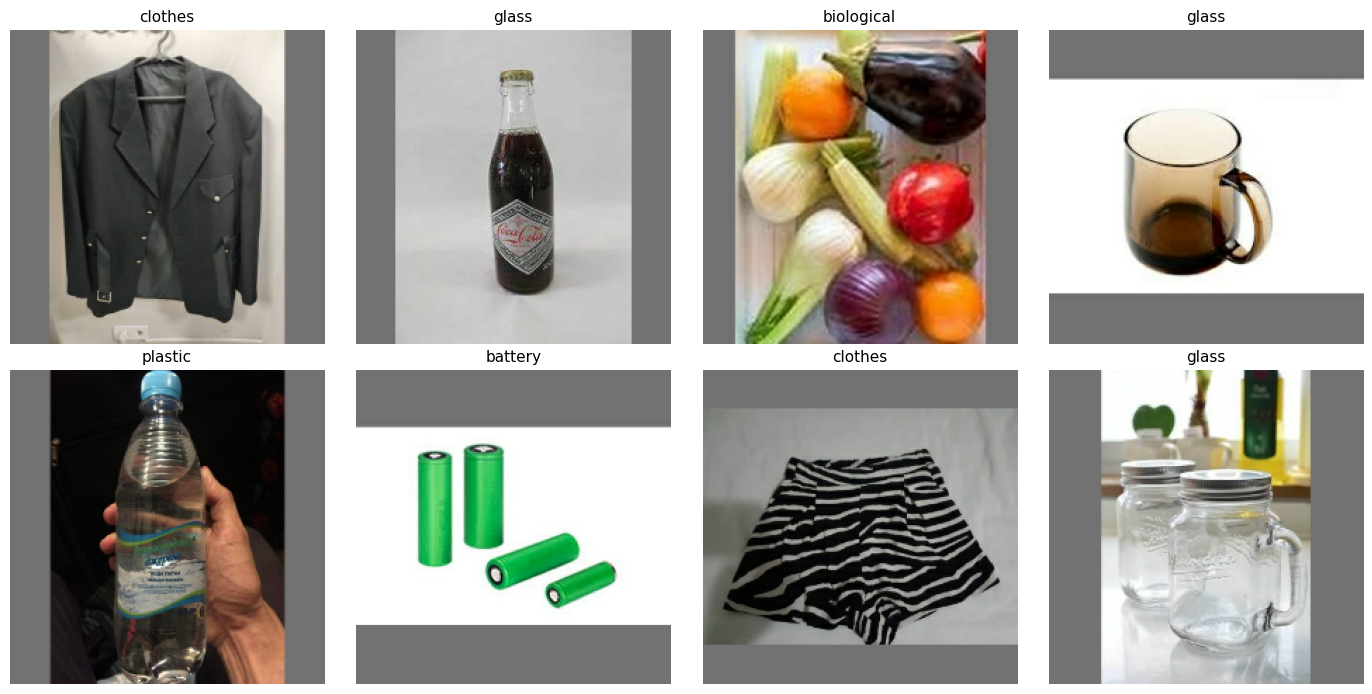

In [5]:
plt.figure(figsize=(14, 7))
for images, labels in raw_train_ds.take(1):
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = np.argmax(labels[i].numpy())
        plt.title(CLASS_NAMES[label_idx], fontsize=11)
        plt.axis("off")
plt.tight_layout()
plt.show()


# Step 5: Data Augmentation #

Model generalization is enhanced through spatial data augmentations, including random horizontal and vertical reflections, rotations, and scaling. Data pipelining performance is optimized using `.cache()` and `.prefetch(AUTOTUNE)` to prevent accelerator starvation.


In [7]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name="data_augmentation")

train_ds = raw_train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = raw_val_ds.cache().prefetch(AUTOTUNE)


# Step 6: Learning Rate Schedule #

Training dynamics are stabilized via a custom learning rate schedule. A linear warm-up phase is applied across early epochs to prevent destabilization of pretrained weights, followed by an exponential decay schedule to achieve smooth convergence.

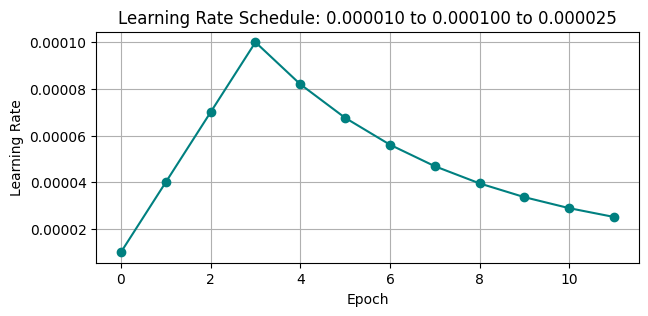

In [8]:
LR_START = 0.00001
LR_MAX = 0.0001 * strategy.num_replicas_in_sync
LR_MIN = 0.00001
LR_RAMPUP_EPOCHS = 3
LR_SUSTAIN_EPOCHS = 0
LR_EXP_DECAY = 0.8

def lrfn(epoch):
    if epoch < LR_RAMPUP_EPOCHS:
        lr = (LR_MAX - LR_START) / LR_RAMPUP_EPOCHS * epoch + LR_START
    elif epoch < LR_RAMPUP_EPOCHS + LR_SUSTAIN_EPOCHS:
        lr = LR_MAX
    else:
        lr = (LR_MAX - LR_MIN) * LR_EXP_DECAY**(epoch - LR_RAMPUP_EPOCHS - LR_SUSTAIN_EPOCHS) + LR_MIN
    return lr

lr_callback = tf.keras.callbacks.LearningRateScheduler(lrfn, verbose=True)

# Plot the Learning Rate Curve
rng = [i for i in range(EPOCHS)]
y = [lrfn(x) for x in rng]
plt.figure(figsize=(7, 3))
plt.plot(rng, y, marker='o', color='teal')
plt.title(f"Learning Rate Schedule: {y[0]:.6f} to {max(y):.6f} to {y[-1]:.6f}")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.grid(True)
plt.show()


# Step 7: Define the Model #

The classification model is constructed via **Transfer Learning** using an `EfficientNetB0` backbone pretrained on the ImageNet dataset.

The base convolutional feature extractor is initially frozen to preserve pretrained feature representations. A `GlobalAveragePooling2D` layer is attached to condense spatial feature maps, a `Dropout` layer is introduced for regularization, and a final `Dense` layer with `softmax` activation is configured to output categorical probability distributions across the 10 waste classes.


In [9]:
with strategy.scope():
    pretrained_base = tf.keras.applications.EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=[*IMAGE_SIZE, 3]
    )
    pretrained_base.trainable = False

    model = models.Sequential([
        pretrained_base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
        metrics=['accuracy']
    )

model.summary()


16705208/16705208 [==============================] - 2s 0us/step
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 efficientnetb0 (Functional  (None, 7, 7, 1280)        4049571   
 )                                                               
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 10)                12810     
                                                                 
Total params: 4062381 (15.50 MB)
Trainable params: 12810 (50.04 KB)
Non-trainable params: 4049571 (15.45 MB)
______________

# Step 8: Train the Model #

Model training is executed via `.fit()`. Both training and validation datasets are passed alongside the dynamic learning rate callback.

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[lr_callback]
)



Epoch 1: LearningRateScheduler setting learning rate to 1e-05.
Epoch 1/12
307/307 [==============================] - 518s 2s/step - loss: 2.4162 - accuracy: 0.0993 - val_loss: 2.2611 - val_accuracy: 0.1424 - lr: 1.0000e-05

Epoch 2: LearningRateScheduler setting learning rate to 4e-05.
Epoch 2/12
307/307 [==============================] - 534s 2s/step - loss: 2.0716 - accuracy: 0.2775 - val_loss: 1.7569 - val_accuracy: 0.5218 - lr: 4.0000e-05

Epoch 3: LearningRateScheduler setting learning rate to 7.000000000000001e-05.
Epoch 3/12
307/307 [==============================] - 538s 2s/step - loss: 1.5944 - accuracy: 0.5573 - val_loss: 1.2633 - val_accuracy: 0.7026 - lr: 7.0000e-05

Epoch 4: LearningRateScheduler setting learning rate to 0.0001.
Epoch 4/12
307/307 [==============================] - 560s 2s/step - loss: 1.2313 - accuracy: 0.6935 - val_loss: 0.9611 - val_accuracy: 0.7878 - lr: 1.0000e-04

Epoch 5: LearningRateScheduler setting learning rate to 8.2e-05.
Epoch 5/12
307/307 [=

# Step 9: Evaluate Predictions #

Model learning dynamics are evaluated by plotting training and validation curves for accuracy and categorical cross-entropy loss.


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curve
ax1.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
ax1.set_title('Classification Accuracy per Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.grid(True)
ax1.legend()

# Loss Curve
ax2.plot(history.history['loss'], label='Train Loss', marker='o')
ax2.plot(history.history['val_loss'], label='Val Loss', marker='o')
ax2.set_title('Cross-Entropy Loss per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

val_loss, val_acc = model.evaluate(val_ds)
print(f"\nFinal Validation Accuracy across {NUM_CLASSES} classes: {val_acc * 100:.2f}%")


# Step 10: Visual Predictions #

Model inference is visualized on unseen validation samples below. Predicted classes, confidence scores, and true class labels are displayed (green indicating correct classification, red indicating misclassification). The final trained model weights are saved to disk.

In [ ]:
for val_images, val_labels in val_ds.take(1):
    predictions = model.predict(val_images)
    break

plt.figure(figsize=(15, 8))
for i in range(8):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(val_images[i].numpy().astype("uint8"))
    
    pred_idx = np.argmax(predictions[i])
    true_idx = np.argmax(val_labels[i].numpy())
    confidence = predictions[i][pred_idx] * 100
    
    is_correct = (pred_idx == true_idx)
    color = "green" if is_correct else "red"
    
    title = f"Pred: {CLASS_NAMES[pred_idx]}\n({confidence:.1f}%)\nTrue: {CLASS_NAMES[true_idx]}"
    plt.title(title, color=color, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save the trained model
model.save("waste_classifier_efficientnet.keras")
print("Model saved to waste_classifier_efficientnet.keras")
